In [2]:

from pathlib import Path

print("Current notebook working directory:")
print(Path.cwd())

print("\nFiles in the current directory:")
for item in Path.cwd().iterdir():
    print(item.name)

print("\nFiles in the parent directory:")
for item in Path.cwd().parent.iterdir():
    print(item.name)


Current notebook working directory:
c:\Users\KOTHEPETA ABHINAV\OneDrive\Desktop\infotect\notebook

Files in the current directory:
01_dataset_inspection.ipynb
02_hourly_data_loading.ipynb

Files in the parent directory:
data
notebook
README.md


In [3]:

from pathlib import Path

data_folder = Path.cwd().parent / "data"

print("Data folder exists:", data_folder.exists())
print("\nFiles inside data folder:")

for file in data_folder.iterdir():
    print(file.name)


Data folder exists: True

Files inside data folder:
experiment_days.csv
price_signals.csv


In [1]:

from pathlib import Path

data_path = Path.cwd().parent / "data" / "data_hourly.csv"

print("Dataset found:", data_path.exists())

if data_path.exists():
    print(f"File size: {data_path.stat().st_size / (1024**3):.2f} GB")


Dataset found: False


In [2]:

import pandas as pd
from pathlib import Path

data_folder = Path.cwd().parent / "data"

experiment_days = pd.read_csv(data_folder / "experiment_days.csv")
price_signals = pd.read_csv(data_folder / "price_signals.csv")

print("Experiment days shape:", experiment_days.shape)
print("Price signals shape:", price_signals.shape)

display(price_signals.head())


Experiment days shape: (267, 4)
Price signals shape: (336, 5)


,Price_signal,Price_profile,Price_level,Hour,Experiment_price_NOK_kWh
0,A_10,A,10,1,1.00
1,A_10,A,10,2,0.99
2,A_10,A,10,3,0.95
3,A_10,A,10,4,0.95
4,A_10,A,10,5,0.96


In [3]:

# Summarize prices by pricing profile
profile_summary = (
    price_signals.groupby("Price_profile")["Experiment_price_NOK_kWh"]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)

profile_summary = profile_summary.rename(columns={
    "count": "Number_of_records",
    "mean": "Average_price",
    "min": "Minimum_price",
    "max": "Maximum_price"
})

display(profile_summary)


,Number_of_records,Average_price,Minimum_price,Maximum_price
Price_profile,,,,
A,48,4.16,0.95,10.13
B,96,5.08,0.95,15.20
C,24,3.95,0.95,10.13
P,96,1.62,0.95,15.08
P0,72,1.17,0.00,30.15


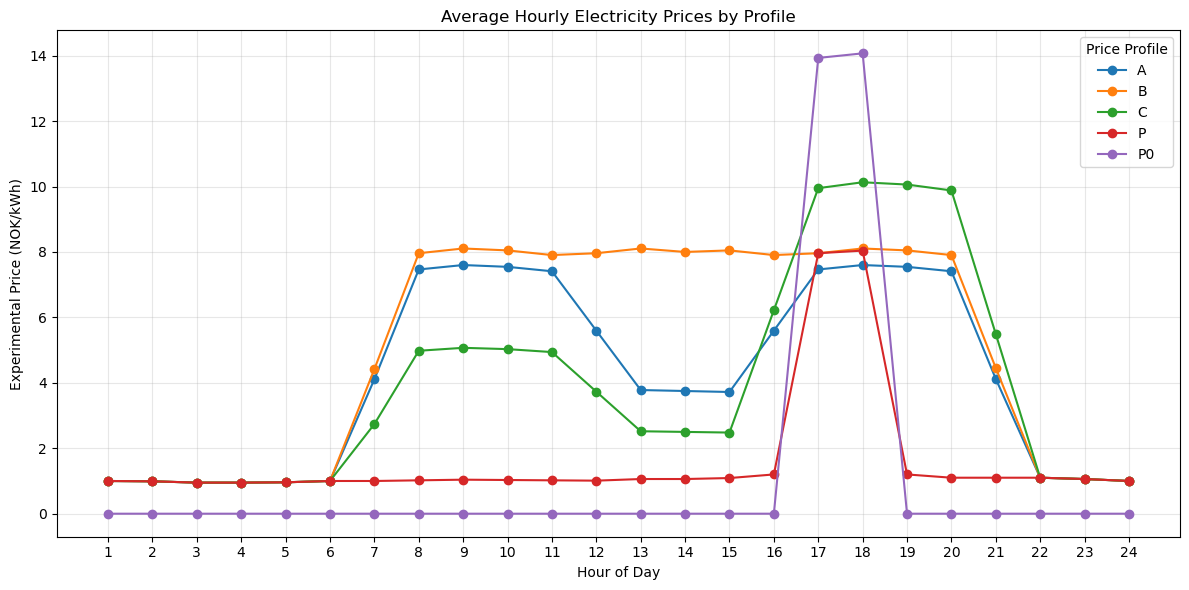

In [4]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for profile in sorted(price_signals["Price_profile"].unique()):
    profile_data = price_signals[
        price_signals["Price_profile"] == profile
    ]

    average_prices = (
        profile_data.groupby("Hour")["Experiment_price_NOK_kWh"]
        .mean()
        .sort_index()
    )

    plt.plot(
        average_prices.index,
        average_prices.values,
        marker="o",
        label=profile
    )

plt.title("Average Hourly Electricity Prices by Profile")
plt.xlabel("Hour of Day")
plt.ylabel("Experimental Price (NOK/kWh)")
plt.xticks(range(1, 25))
plt.legend(title="Price Profile")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## 5. Hourly Electricity Price Pattern Analysis

The line chart compares average hourly electricity prices across five pricing profiles: A, B, C, P, and P0.

### Key Observations

- Profile A shows higher prices during selected daytime periods.
- Profile B maintains relatively high prices throughout much of the day.
- Profile C shows higher prices during selected morning and evening hours.
- Profile P has a short evening price peak, while prices remain low during most other hours.
- Profile P0 has zero prices during many hours and a sharp evening price peak.

### Conclusion

The pricing profiles follow different hourly patterns. These differences provide a basis for exploring whether electricity consumption changes under different price conditions.

Consumption effects and causal conclusions will be investigated after the hourly household dataset is loaded and the experiment design is validated.


In [5]:

profile_summary = (
    price_signals.groupby("Price_profile")["Experiment_price_NOK_kWh"]
    .agg(["mean", "min", "max"])
    .round(2)
    .sort_values("mean", ascending=False)
)

display(profile_summary)


,mean,min,max
Price_profile,,,
B,5.08,0.95,15.20
A,4.16,0.95,10.13
C,3.95,0.95,10.13
P,1.62,0.95,15.08
P0,1.17,0.00,30.15


In [6]:

from pathlib import Path

data_path = Path.cwd().parent / "data" / "data_hourly.csv"

print("Dataset found:", data_path.exists())

if data_path.exists():
    print(f"File size: {data_path.stat().st_size / (1024**3):.2f} GB")


Dataset found: True
File size: 0.98 GB


In [7]:

import pandas as pd

hourly_sample = pd.read_csv(data_path, nrows=10)

print("Sample shape:", hourly_sample.shape)
print("\nColumns:")
print(hourly_sample.columns.tolist())

display(hourly_sample)


Sample shape: (10, 12)

Columns:
['ID', 'From', 'Date', 'Hour', 'Participation_Phase', 'Demand_kWh', 'Price_signal', 'Experiment_price_NOK_kWh', 'Temperature', 'Temperature24', 'Temperature48', 'Temperature72']


,ID,From,Date,Hour,Participation_Phase,Demand_kWh,Price_signal,Experiment_price_NOK_kWh,Temperature,Temperature24,Temperature48,Temperature72
0,Exp_43,2020-02-01T00:00:00Z,2020-02-01,1,Phase_1,0.348,NaN,NaN,7.6,6.1,5.0,4.4
1,Exp_43,2020-02-01T01:00:00Z,2020-02-01,2,Phase_1,0.589,NaN,NaN,8.2,6.2,5.1,4.4
2,Exp_43,2020-02-01T02:00:00Z,2020-02-01,3,Phase_1,0.358,NaN,NaN,8.4,6.3,5.3,4.5
3,Exp_43,2020-02-01T03:00:00Z,2020-02-01,4,Phase_1,0.582,NaN,NaN,8.4,6.4,5.4,4.5
4,Exp_43,2020-02-01T04:00:00Z,2020-02-01,5,Phase_1,0.364,NaN,NaN,8.2,6.5,5.5,4.6
5,Exp_43,2020-02-01T05:00:00Z,2020-02-01,6,Phase_1,0.337,NaN,NaN,8.0,6.6,5.6,4.7
6,Exp_43,2020-02-01T06:00:00Z,2020-02-01,7,Phase_1,0.621,NaN,NaN,8.1,6.7,5.7,4.7
7,Exp_43,2020-02-01T07:00:00Z,2020-02-01,8,Phase_1,2.120,NaN,NaN,8.1,6.8,5.8,4.8
8,Exp_43,2020-02-01T08:00:00Z,2020-02-01,9,Phase_1,3.847,NaN,NaN,7.6,6.9,5.9,4.9
9,Exp_43,2020-02-01T09:00:00Z,2020-02-01,10,Phase_1,3.516,NaN,NaN,7.4,6.9,6.0,5.0


In [8]:

print("Data types:")
print(hourly_sample.dtypes)

print("\nMissing values in the 10-row sample:")
print(hourly_sample.isnull().sum())

print("\nNumeric summary:")
display(hourly_sample.describe().round(3))


Data types:
ID                           object
From                         object
Date                         object
Hour                          int64
Participation_Phase          object
Demand_kWh                  float64
Price_signal                float64
Experiment_price_NOK_kWh    float64
Temperature                 float64
Temperature24               float64
Temperature48               float64
Temperature72               float64
dtype: object

Missing values in the 10-row sample:
ID                           0
From                         0
Date                         0
Hour                         0
Participation_Phase          0
Demand_kWh                   0
Price_signal                10
Experiment_price_NOK_kWh    10
Temperature                  0
Temperature24                0
Temperature48                0
Temperature72                0
dtype: int64

Numeric summary:


,Hour,Demand_kWh,Price_signal,Experiment_price_NOK_kWh,Temperature,Temperature24,Temperature48,Temperature72
count,10.000,10.000,0.0,0.0,10.00,10.000,10.000,10.000
mean,5.500,1.268,NaN,NaN,8.00,6.540,5.530,4.650
std,3.028,1.380,NaN,NaN,0.35,0.288,0.333,0.207
min,1.000,0.337,NaN,NaN,7.40,6.100,5.000,4.400
25%,3.250,0.360,NaN,NaN,7.70,6.325,5.325,4.500
50%,5.500,0.585,NaN,NaN,8.10,6.550,5.550,4.650
75%,7.750,1.745,NaN,NaN,8.20,6.775,5.775,4.775
max,10.000,3.847,NaN,NaN,8.40,6.900,6.000,5.000


In [9]:

import pandas as pd

chunk_size = 100_000

total_rows = 0
missing_counts = None
phase_counts = {}
participant_ids = set()
date_min = None
date_max = None

for chunk in pd.read_csv(
    data_path,
    chunksize=chunk_size,
    low_memory=False
):
    total_rows += len(chunk)

    # Count missing values across all rows
    counts = chunk.isna().sum()
    if missing_counts is None:
        missing_counts = counts
    else:
        missing_counts = missing_counts.add(counts, fill_value=0)

    # Count observations by participation phase
    for phase, count in chunk["Participation_Phase"].value_counts().items():
        phase_counts[phase] = phase_counts.get(phase, 0) + count

    # Track participants and date range
    participant_ids.update(chunk["ID"].dropna().unique())

    dates = pd.to_datetime(chunk["Date"], errors="coerce").dropna()
    if not dates.empty:
        chunk_min, chunk_max = dates.min(), dates.max()
        date_min = chunk_min if date_min is None else min(date_min, chunk_min)
        date_max = chunk_max if date_max is None else max(date_max, chunk_max)

print("Total rows:", total_rows)
print("\nMissing values:")
print(missing_counts.astype("int64"))

print("\nParticipation phases:")
print(phase_counts)

print("\nUnique participants:", len(participant_ids))
print("Date range:", date_min, "to", date_max)


Total rows: 13515600

Missing values:
ID                                 0
From                               0
Date                               0
Hour                               0
Participation_Phase                0
Demand_kWh                         0
Price_signal                11986392
Experiment_price_NOK_kWh    11986392
Temperature                        0
Temperature24                      0
Temperature48                      0
Temperature72                      0
dtype: int64

Participation phases:
{'Phase_1': 1335600, 'Phase_2': 12180000}

Unique participants: 4429
Date range: 2020-01-06 00:00:00 to 2021-03-26 00:00:00


In [10]:

import pandas as pd

phase_results = {}

for chunk in pd.read_csv(
    data_path,
    chunksize=100_000,
    low_memory=False
):
    grouped = chunk.groupby("Participation_Phase").agg(
        Total_Rows=("ID", "size"),
        Missing_Price_Signal=("Price_signal", lambda x: x.isna().sum()),
        Missing_Experiment_Price=(
            "Experiment_price_NOK_kWh",
            lambda x: x.isna().sum()
        )
    )

    for phase, row in grouped.iterrows():
        if phase not in phase_results:
            phase_results[phase] = row.copy()
        else:
            phase_results[phase] += row

phase_summary = pd.DataFrame(phase_results).T

phase_summary["Missing_Price_Signal_Pct"] = (
    phase_summary["Missing_Price_Signal"]
    / phase_summary["Total_Rows"] * 100
).round(2)

display(phase_summary)


,Total_Rows,Missing_Price_Signal,Missing_Experiment_Price,Missing_Price_Signal_Pct
Phase_1,1335600,1267152,1267152,94.88
Phase_2,12180000,10719240,10719240,88.01
